In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, json, time
os.chdir('/content/drive/MyDrive/network-intrusion-ml')
sys.path.append('/content/drive/MyDrive/network-intrusion-ml')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import (PROCESSED_DIR, METRIC_DIR, TABLE_DIR, save_fig, save_table,
                       log_experiment, RANDOM_STATE)
from src.preprocessing import signed_log1p

sns.set_theme(style="whitegrid")

with open(METRIC_DIR / "label_mapping.json") as f:
    label_mapping = json.load(f)
with open(METRIC_DIR / "feature_sets.json") as f:
    feature_sets = json.load(f)

FEATURES = feature_sets["CORR_FILTERED"]
class_names = [c for c, i in sorted(label_mapping.items(), key=lambda kv: kv[1])]
print("Features:", len(FEATURES))

Mounted at /content/drive
Features: 48


In [2]:
from sklearn.model_selection import StratifiedKFold

cv_df = pd.read_parquet(PROCESSED_DIR / "cv_sample.parquet")
y_multi = cv_df["Label_Group"].map(label_mapping).values

# Signed-log version of the features, used by every strategy
X_log = pd.DataFrame(signed_log1p(cv_df[FEATURES].values), columns=FEATURES).astype("float32")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(skf.split(X_log, cv_df["Label_Group"]))
for k, (tr, va) in enumerate(folds, 1):
    c = cv_df["Label_Group"].iloc[va].value_counts()
    print(f"Fold {k}: quiz on {len(va):,} rows | Heartbleed {c.get('Heartbleed', 0)}, "
          f"Infiltration {c.get('Infiltration', 0)}")

Fold 1: quiz on 101,514 rows | Heartbleed 1, Infiltration 6
Fold 2: quiz on 101,514 rows | Heartbleed 2, Infiltration 5
Fold 3: quiz on 101,514 rows | Heartbleed 2, Infiltration 6
Fold 4: quiz on 101,514 rows | Heartbleed 2, Infiltration 6
Fold 5: quiz on 101,514 rows | Heartbleed 2, Infiltration 6


In [3]:
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             precision_recall_fscore_support)

STRATEGIES = {
    "original": "Original data",
    "class_weights": "Class weights (sqrt)",
    "undersampling": "Undersampling (cap 20,000)",
    "smote": "SMOTE (small classes to 2,000)",
}
CAP_UNDER = 20_000
SMOTE_TARGET = 2_000
FOLD_CSV = TABLE_DIR / "06b_imbalance_fold_metrics.csv"

def make_xgb():
    return XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.3,
                         tree_method="hist", n_jobs=-1,
                         random_state=RANDOM_STATE, verbosity=0)

def apply_strategy(key, X_tr, y_tr):
    """Returns (X, y, sample_weight). Only ever applied to TRAINING folds."""
    counts = np.bincount(y_tr)
    if key == "original":
        return X_tr, y_tr, None
    if key == "class_weights":
        w_class = np.sqrt(counts.max() / counts)       # rarer class -> bigger weight
        return X_tr, y_tr, w_class[y_tr]
    if key == "undersampling":
        strat = {c: min(n, CAP_UNDER) for c, n in enumerate(counts)}
        Xr, yr = RandomUnderSampler(sampling_strategy=strat, random_state=RANDOM_STATE).fit_resample(X_tr, y_tr)
        return Xr, yr, None
    if key == "smote":
        strat = {c: SMOTE_TARGET for c, n in enumerate(counts) if n < SMOTE_TARGET}
        Xr, yr = SMOTE(sampling_strategy=strat, k_neighbors=5,
                       random_state=RANDOM_STATE).fit_resample(X_tr, y_tr)
        return Xr, yr, None

def run_imbalance():
    rows = pd.read_csv(FOLD_CSV).to_dict("records") if FOLD_CSV.exists() else []
    done = {r["strategy"] for r in rows}

    for key, label in STRATEGIES.items():
        if key in done:
            print(f"[skip] {label} (already saved)")
            continue
        oof = np.zeros(len(y_multi), dtype=np.int8)
        for k, (tr, va) in enumerate(folds, 1):
            X_fit, y_fit, w = apply_strategy(key, X_log.iloc[tr], y_multi[tr])
            model = make_xgb()
            t0 = time.time()
            model.fit(X_fit, y_fit, sample_weight=w)
            fit_s = time.time() - t0

            pred = model.predict(X_log.iloc[va])
            y_v = y_multi[va]
            oof[va] = pred
            present = np.unique(y_v)
            rows.append({"strategy": key, "fold": k, "train_rows_used": len(y_fit),
                         "train_seconds": round(fit_s, 1),
                         "accuracy": accuracy_score(y_v, pred),
                         "macro_f1": f1_score(y_v, pred, labels=present, average="macro", zero_division=0),
                         "weighted_f1": f1_score(y_v, pred, average="weighted", zero_division=0)})
            print(f"{label:32s} fold {k}/5 | rows {len(y_fit):7,} | fit {fit_s:6.1f}s | macro-F1 {rows[-1]['macro_f1']:.4f}")

        np.save(METRIC_DIR / f"06b_oof_{key}.npy", oof)
        pd.DataFrame(rows).to_csv(FOLD_CSV, index=False)      # saved after each strategy

        mine = pd.DataFrame([r for r in rows if r["strategy"] == key])
        log_experiment(
            experiment_id=f"EXP-04_imbalance_{key}", task="Experiment B: multi-class (Label_Group)",
            model="XGBoost", features=f"CORR_FILTERED ({len(FEATURES)}), signed-log transformed",
            preprocessing=f"imbalance strategy: {label} (training folds only)",
            hyperparameters="baseline defaults",
            split="stratified 5-fold CV on the CV sample (inside the training set)",
            metrics={k2: round(float(mine[k2].mean()), 4) for k2 in ["accuracy", "macro_f1", "weighted_f1"]},
            notes="same folds as 06a; out-of-fold predictions saved in results/metrics",
        )
    print("Done.")

print("Ready.")

Ready.


In [5]:
run_imbalance()

[skip] Original data (already saved)
Class weights (sqrt)             fold 1/5 | rows 406,056 | fit   79.1s | macro-F1 0.9620
Class weights (sqrt)             fold 2/5 | rows 406,056 | fit   77.5s | macro-F1 0.9755
Class weights (sqrt)             fold 3/5 | rows 406,056 | fit   80.9s | macro-F1 0.9322
Class weights (sqrt)             fold 4/5 | rows 406,056 | fit   76.7s | macro-F1 0.9581
Class weights (sqrt)             fold 5/5 | rows 406,056 | fit   79.5s | macro-F1 0.9496
[logged experiment] EXP-04_imbalance_class_weights
Undersampling (cap 20,000)       fold 1/5 | rows  83,016 | fit   15.7s | macro-F1 0.9853
Undersampling (cap 20,000)       fold 2/5 | rows  83,016 | fit   19.0s | macro-F1 0.9852
Undersampling (cap 20,000)       fold 3/5 | rows  83,016 | fit   15.6s | macro-F1 0.9782
Undersampling (cap 20,000)       fold 4/5 | rows  83,017 | fit   16.9s | macro-F1 0.9677
Undersampling (cap 20,000)       fold 5/5 | rows  83,015 | fit   17.5s | macro-F1 0.9783
[logged experiment] EX

                      strategy macro-F1 (mean ± std) change vs original (mean ± std)  Bot F1  Infiltration recall  Heartbleed F1  false-alarm rate (%)  train rows used  sec per fold
                 Original data       0.9592 ± 0.0251                 0.0000 ± 0.0000   0.922                0.724          0.889                 0.117           406056          77.0
          Class weights (sqrt)       0.9555 ± 0.0160                -0.0037 ± 0.0271   0.932                0.793          0.889                 0.119           406056          78.7
    Undersampling (cap 20,000)       0.9790 ± 0.0072                 0.0198 ± 0.0273   0.897                0.862          1.000                 0.200            83016          16.9
SMOTE (small classes to 2,000)       0.9745 ± 0.0118                 0.0153 ± 0.0281   0.929                0.897          1.000                 0.107           411407          81.3
[saved table] /content/drive/MyDrive/network-intrusion-ml/results/tables/06b_imbalance_sum

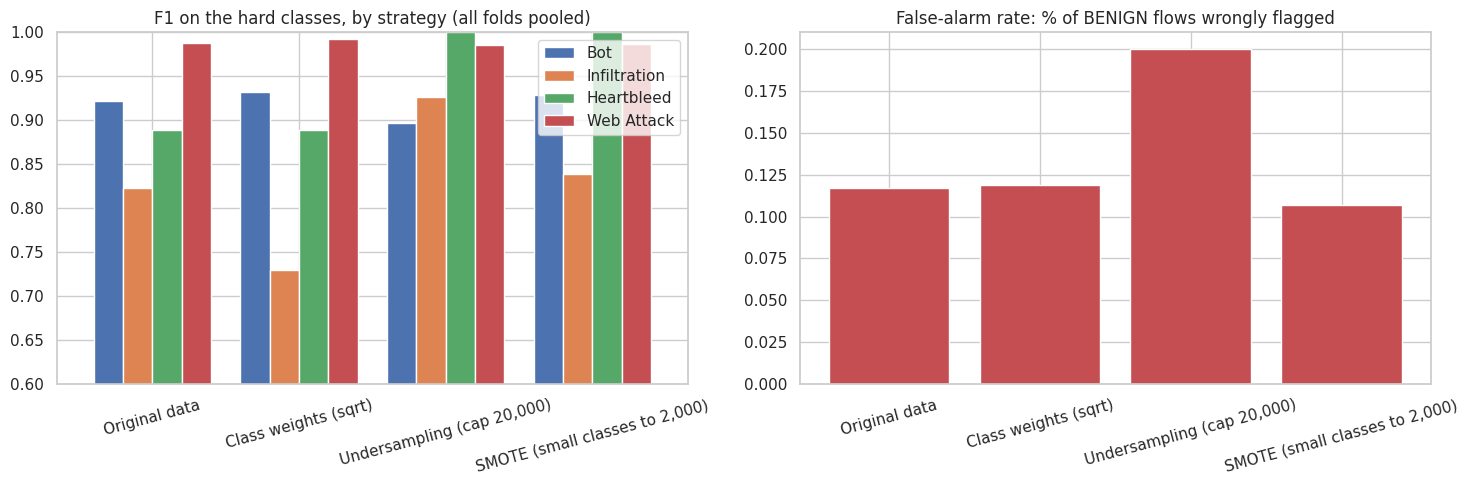

In [6]:
fold_df = pd.read_csv(FOLD_CSV)
base = fold_df[fold_df["strategy"] == "original"].set_index("fold")["macro_f1"]

def pm(s, nd=4):
    return f"{s.mean():.{nd}f} ± {s.std():.{nd}f}"

rows, per_class = [], {}
for key, label in STRATEGIES.items():
    g = fold_df[fold_df["strategy"] == key].set_index("fold")
    oof = np.load(METRIC_DIR / f"06b_oof_{key}.npy")
    p, r, f, s = precision_recall_fscore_support(
        y_multi, oof, labels=list(range(len(class_names))), zero_division=0)
    f1c, rec = dict(zip(class_names, f)), dict(zip(class_names, r))
    per_class[label] = f1c
    diff = g["macro_f1"] - base
    rows.append({
        "strategy": label,
        "macro-F1 (mean ± std)": pm(g["macro_f1"]),
        "change vs original (mean ± std)": pm(diff),
        "Bot F1": round(f1c["Bot"], 3),
        "Infiltration recall": round(rec["Infiltration"], 3),
        "Heartbleed F1": round(f1c["Heartbleed"], 3),
        "false-alarm rate (%)": round((1 - rec["BENIGN"]) * 100, 3),
        "train rows used": int(g["train_rows_used"].mean()),
        "sec per fold": round(g["train_seconds"].mean(), 1),
    })

summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
save_table(summary, "06b_imbalance_summary", index=False)

# Chart
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
pc = pd.DataFrame(per_class).T[["Bot", "Infiltration", "Heartbleed", "Web Attack"]]
pc.plot.bar(ax=axes[0], width=0.8)
axes[0].set_ylim(0.6, 1.0)
axes[0].set_title("F1 on the hard classes, by strategy (all folds pooled)")
axes[0].tick_params(axis="x", rotation=15)
fa = summary.set_index("strategy")["false-alarm rate (%)"]
axes[1].bar(fa.index, fa.values, color="#C44E52")
axes[1].set_title("False-alarm rate: % of BENIGN flows wrongly flagged")
axes[1].tick_params(axis="x", rotation=15)
save_fig("06b_imbalance_comparison")
plt.show()

In [7]:
from src.utils import FIG_DIR
for p in sorted(TABLE_DIR.glob("06b_*")) + sorted(METRIC_DIR.glob("06b_*")) + sorted(FIG_DIR.glob("06b_*")):
    print(p.name)

06b_imbalance_fold_metrics.csv
06b_imbalance_summary.csv
06b_oof_class_weights.npy
06b_oof_original.npy
06b_oof_smote.npy
06b_oof_undersampling.npy
06b_imbalance_comparison.png


[saved figure] /content/drive/MyDrive/network-intrusion-ml/results/figures/06b_imbalance_comparison.png


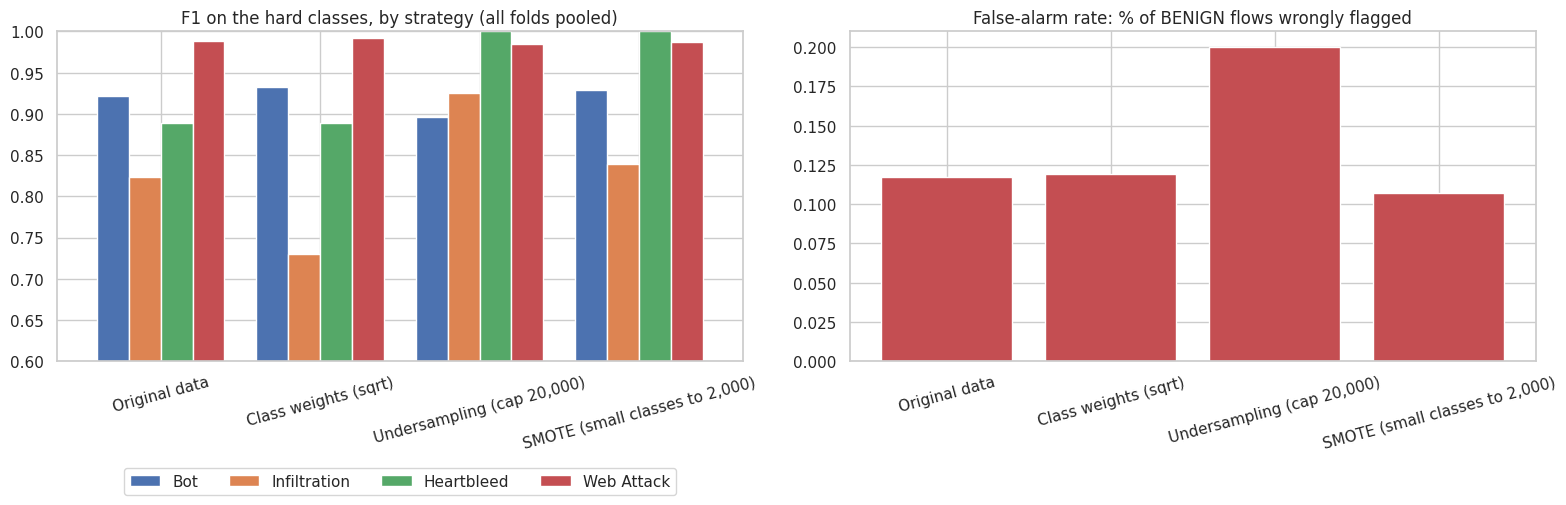

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
pc.plot.bar(ax=axes[0], width=0.8)
axes[0].set_ylim(0.6, 1.0)
axes[0].set_title("F1 on the hard classes, by strategy (all folds pooled)")
axes[0].tick_params(axis="x", rotation=15)
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=4)
fa = summary.set_index("strategy")["false-alarm rate (%)"]
axes[1].bar(fa.index, fa.values, color="#C44E52")
axes[1].set_title("False-alarm rate: % of BENIGN flows wrongly flagged")
axes[1].tick_params(axis="x", rotation=15)
save_fig("06b_imbalance_comparison")
plt.show()